# Assignment 3 — Module 3: Evolutionary and Swarm Optimization

**Student Name:** Arendra Singh Rajput  
**Roll No.:** 2023BTCSE003  
**Enrollment No.:** JLU08391  
**Course:** B.Tech CSE, 4th Year  
**Subject:** Soft Computing Exercise  

---

## Practical 1: Population Representation and Encoding Methods

### Aim
To create and represent a population of individuals using binary, real-valued and permutation encodings in Python.

### Theory
In a Genetic Algorithm (GA) each candidate solution is an **individual** whose genes form a **chromosome**. The way a solution is written into a chromosome is called its **encoding**:

- **Binary encoding:** each variable is stored as a string of bits, decoded as $x = x_{low} + \frac{k(x_{high}-x_{low})}{2^{n}-1}$ where $k$ is the integer value of the bit string.
- **Real-valued encoding:** each gene is a floating-point number directly in the search range.
- **Permutation encoding:** each chromosome is an ordering of items (used for routing / scheduling problems).

A **population** is a collection of such individuals; its size is a key GA parameter.

### Setting up parameters and random generator

In [1]:
import numpy as np
import matplotlib.pyplot as plt

gen_rng = np.random.default_rng(42)     # reproducible random numbers

POP_SIZE = 6        # number of individuals
N_VARS = 3          # number of decision variables
BITS_PER_VAR = 8    # bits used per variable (binary encoding)
LOW, HIGH = -5.12, 5.12   # search bounds
N_CITIES = 5        # size of permutation

### Binary encoding

In [2]:
def create_binary_population(size, n_vars, bits):
    # Each individual has n_vars * bits genes, each gene is 0 or 1
    return gen_rng.integers(0, 2, size=(size, n_vars * bits))

def decode_binary(chromosome, n_vars, bits, low, high):
    # Split chromosome into variables and convert each bit-string to a real number
    values = []
    for v in range(n_vars):
        gene = chromosome[v*bits:(v+1)*bits]
        k = int("".join(map(str, gene)), 2)
        values.append(low + k * (high - low) / (2**bits - 1))
    return np.array(values)

bin_pop = create_binary_population(POP_SIZE, N_VARS, BITS_PER_VAR)
print("Binary population shape:", bin_pop.shape)
for i, ind in enumerate(bin_pop):
    print(f"Ind {i}: {''.join(map(str, ind))}  ->  decoded = {np.round(decode_binary(ind, N_VARS, BITS_PER_VAR, LOW, HIGH), 3)}")

Binary population shape: (6, 24)
Ind 0: 011001010011111110101001  ->  decoded = [-1.064 -2.59   1.667]
Ind 1: 110110000110110101100101  ->  decoded = [ 3.554 -0.743 -1.064]
Ind 2: 111000001011110100100010  ->  decoded = [ 3.875  2.47  -3.755]
Ind 3: 001000111001110011011010  ->  decoded = [-3.715  1.144  3.634]
Ind 4: 011010101111010110110000  ->  decoded = [-0.863  4.718  1.948]
Ind 5: 011011011111011010001000  ->  decoded = [-0.743  4.759  0.341]


### Real-valued encoding

In [3]:
def create_real_population(size, n_vars, low, high):
    # Each gene is a random float uniformly drawn from [low, high]
    return gen_rng.uniform(low, high, size=(size, n_vars))

real_pop = create_real_population(POP_SIZE, N_VARS, LOW, HIGH)
print("Real-valued population shape:", real_pop.shape)
print(np.round(real_pop, 3))

Real-valued population shape: (6, 3)
[[ 3.619 -2.724 -4.523]
 [-2.239 -2.114  1.658]
 [ 0.584  2.907  1.683]
 [-0.959  3.216 -3.41 ]
 [-4.887 -4.198  2.277]
 [-0.39  -3.469  0.011]]


### Permutation encoding

In [4]:
def create_permutation_population(size, n_items):
    # Each individual is a random ordering of the item indices 0..n_items-1
    return np.array([gen_rng.permutation(n_items) for _ in range(size)])

perm_pop = create_permutation_population(POP_SIZE, N_CITIES)
print("Permutation population shape:", perm_pop.shape)
print(perm_pop)

Permutation population shape: (6, 5)
[[4 2 0 3 1]
 [3 1 4 0 2]
 [1 4 3 0 2]
 [4 2 3 0 1]
 [4 0 3 1 2]
 [3 2 1 4 0]]


### Visualizing the three encodings

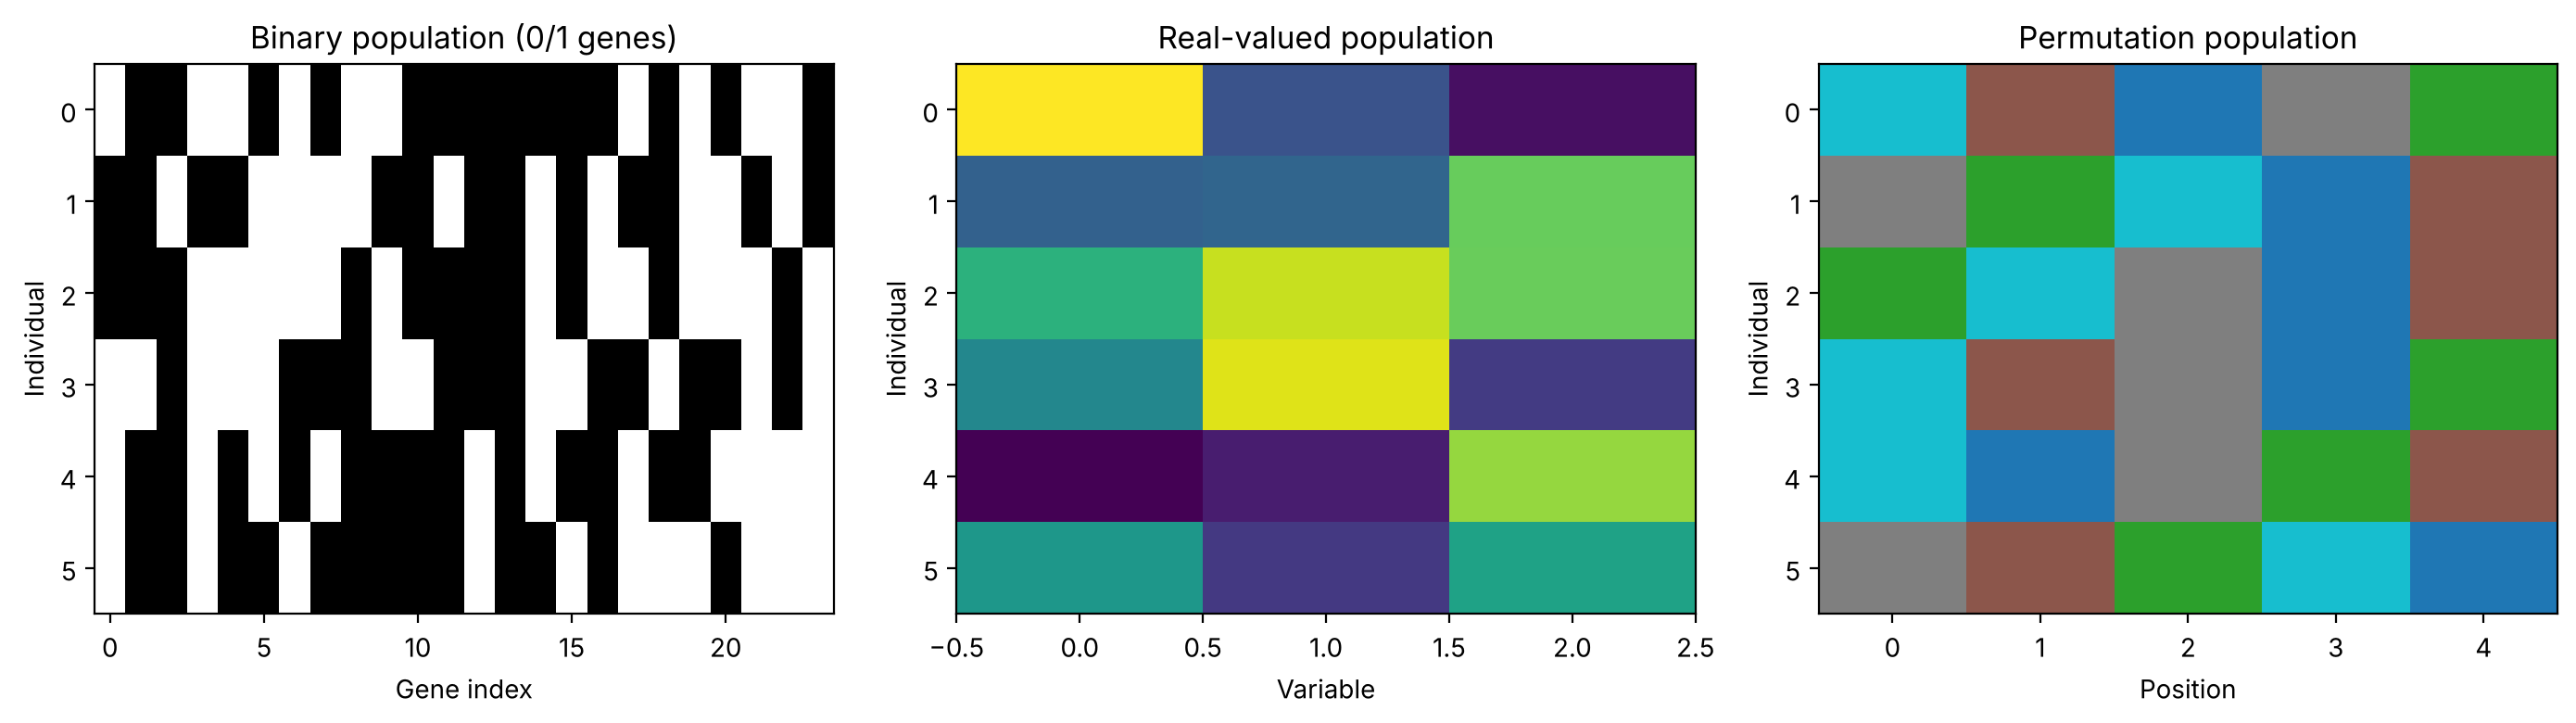

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
ax[0].imshow(bin_pop, cmap='Greys', aspect='auto')
ax[0].set_title('Binary population (0/1 genes)')
ax[0].set_xlabel('Gene index'); ax[0].set_ylabel('Individual')

ax[1].imshow(real_pop, cmap='viridis', aspect='auto')
ax[1].set_title('Real-valued population')
ax[1].set_xlabel('Variable'); ax[1].set_ylabel('Individual')

ax[2].imshow(perm_pop, cmap='tab10', aspect='auto')
ax[2].set_title('Permutation population')
ax[2].set_xlabel('Position'); ax[2].set_ylabel('Individual')
plt.tight_layout(); plt.show()

### Observation
- Binary chromosomes are strings of 0s and 1s; decoding maps each bit-string to a value inside the search range $[-5.12, 5.12]$.
- Real-valued chromosomes need no decoding and are the most natural choice for continuous problems.
- Permutation chromosomes never contain repeated items, which is why they suit ordering problems such as the travelling salesman problem.

### Conclusion
Created and visualized populations using binary, real-valued and permutation encodings, and decoded binary chromosomes back to real values.